## Baseline Experiments Runner

- The baseline algorithms (TOMC with dynamic exploration time, KL-SPMD) come from `ie692_rl.core`
  and `ie692_rl.enhancements.bregman_spmd` (the KL step).
- The environments come from `ie692_rl.envs`. This notebook runs training, saves the per-iteration
  history (estimated V(s₀), observations, exact gap) and the final policy, and produces plots.
- Raw transitions are no longer written to CSV: the sampler runs inside a compiled kernel and a
  GridWorld run is tens of millions of transitions.
- Install the package first (`pip install -e ".[notebooks]"`, see the README).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from ie692_rl.core import TOMC, ExactScorer, run_spmd
from ie692_rl.enhancements.bregman_spmd import KL
from ie692_rl.envs import Blackjack, GridWorld

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.style.use("ggplot")

In [2]:
RUN_ENVIRONMENTS = ["gridworld", "blackjack"]
BUDGETS = {"gridworld": 3_000_000, "blackjack": 120_000}  # environment steps per run
ETA = 0.1
BIAS = 0.01
PI_MIN = None  # None -> (1 - gamma) / n_actions
SEED = 42
OUTPUT_DIR = REPO / "results" / "notebook_baseline"

# Optional exploratory search; tune.py runs the full grid search from config.cfg.
RUN_TUNING = False
ETA_GRID = [0.05, 0.1, 0.2]
BIAS_GRID = [0.005, 0.01, 0.02]
PI_MIN_MULTIPLIERS = [0.5, 1.0, 1.5]
TUNING_FRACTION = 0.1  # of each environment's budget

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
def create_env(name):
    if name == "gridworld":
        return GridWorld()
    if name == "blackjack":
        return Blackjack()  # values are reported at (total 8, dealer shows 3)
    raise ValueError(f"Unknown environment: {name}")


def run_trial(name, eta=ETA, bias=BIAS, pi_min=PI_MIN, budget=None, seed=SEED, output_root=OUTPUT_DIR):
    env = create_env(name)
    budget = BUDGETS[name] if budget is None else budget
    folder = Path(output_root) / name
    folder.mkdir(parents=True, exist_ok=True)
    result = run_spmd(env, TOMC(bias=bias, pi_min=pi_min), KL(), eta, budget, seed, scorer=ExactScorer(env))
    history = pd.DataFrame([r.as_dict() for r in result.history if r.status == "updated"])
    status = {
        "environment": name,
        "eta": eta,
        "bias": bias,
        "pi_min": pi_min,
        "seed": seed,
        "budget": budget,
        "updates": len(history),
        "final_status": result.history[-1].status,
        "total_observations": result.history[-1].cumulative_observations,
        "final_exact_gap": result.history[-1].gap,
    }
    (folder / "status.json").write_text(json.dumps(status, indent=2))
    if history.empty:
        print(f"{name}: no completed SPMD update within {budget:,} observations")
        return status, None
    history["running_average_V"] = history["estimated_value"].expanding().mean()
    history.to_csv(folder / "history.csv", index=False)
    pd.DataFrame(result.policy, columns=[f"action_{a}" for a in range(env.n_actions)]).rename_axis(
        "state"
    ).to_csv(folder / "policy.csv")
    print(
        f"{name}: {len(history)} updates, {status['total_observations']:,} observations, "
        f"final exact gap {status['final_exact_gap']:.4f}"
    )
    return status, history

In [4]:
training_results = {}
for name in RUN_ENVIRONMENTS:
    status, history = run_trial(name)
    training_results[name] = (status, history)

pd.DataFrame([item[0] for item in training_results.values()])

gridworld: 12 updates, 3,000,000 observations, final exact gap 0.2519


blackjack: 71 updates, 120,000 observations, final exact gap 0.0560


,environment,eta,bias,pi_min,seed,budget,updates,final_status,total_observations,final_exact_gap
0,gridworld,0.1,0.01,None,42,3000000,12,budget,3000000,0.251904
1,blackjack,0.1,0.01,None,42,120000,71,budget,120000,0.056004


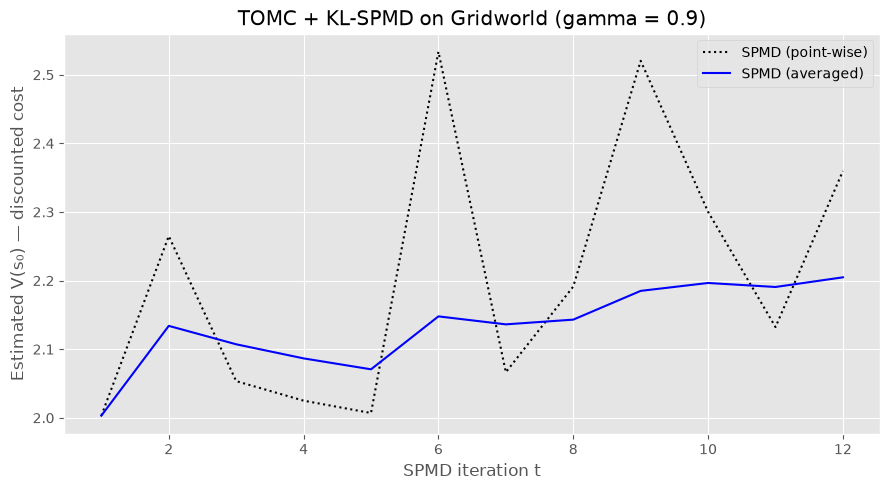

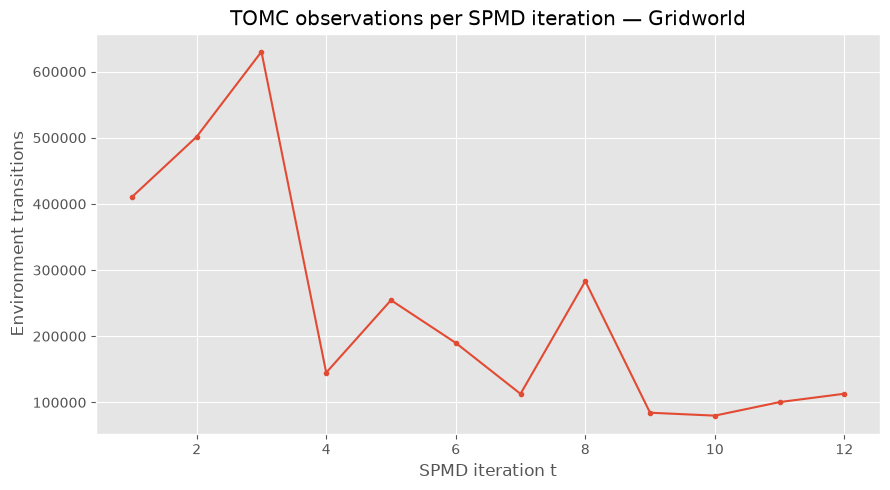

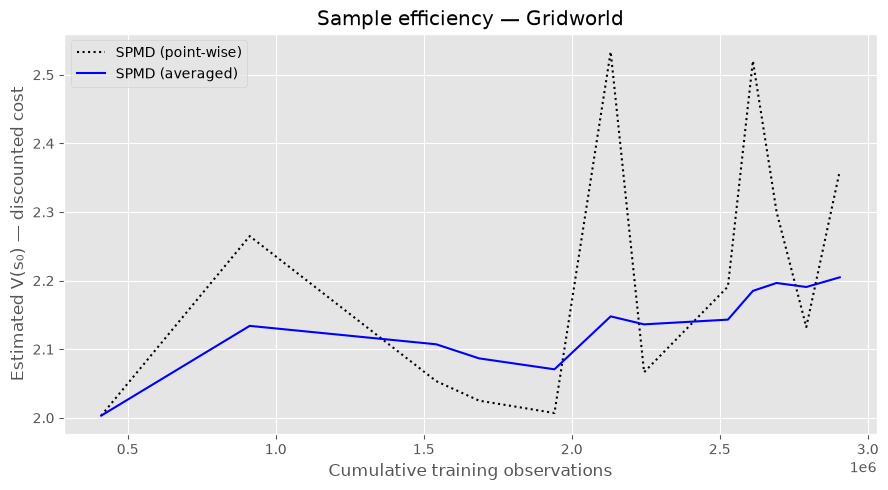

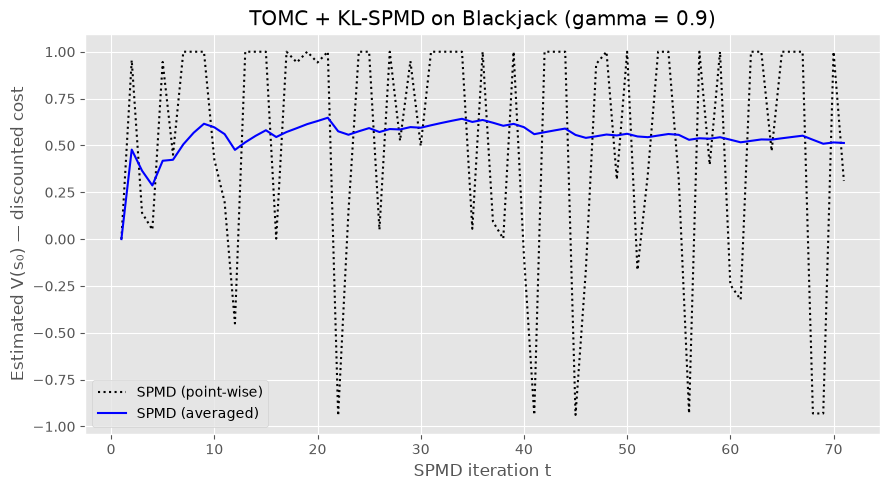

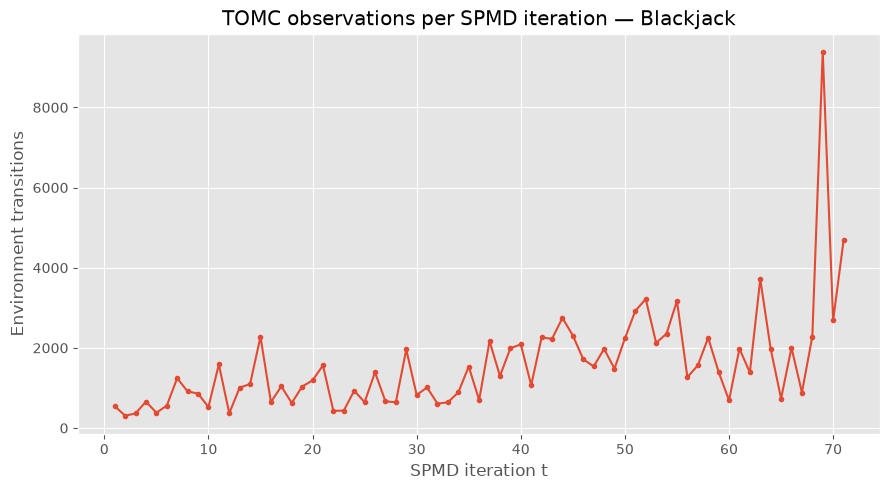

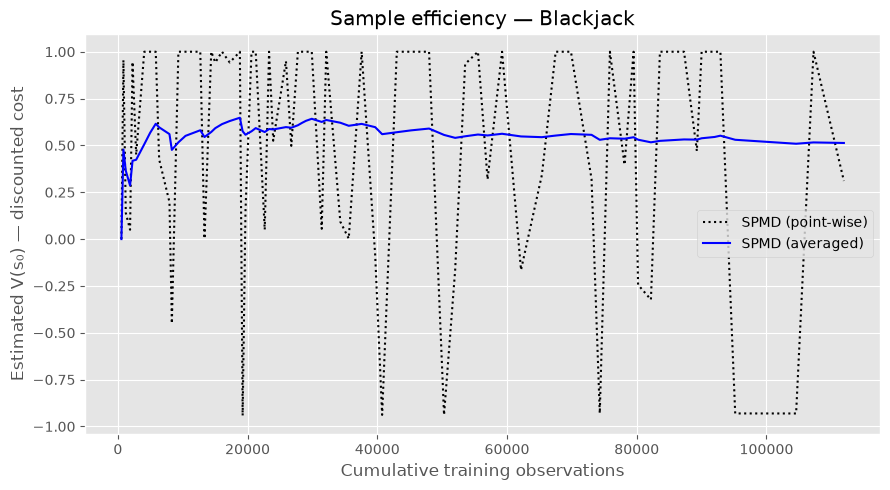

In [5]:
def plot_baseline(name, history, output_root=OUTPUT_DIR):
    if history is None or history.empty:
        print(f"{name}: no completed SPMD updates to plot")
        return

    folder = Path(output_root) / name
    x = history["iteration"]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, history["estimated_value"], label="SPMD (point-wise)", linestyle="dotted", color="black")
    ax.plot(x, history["running_average_V"], label="SPMD (averaged)", linestyle="solid", color="blue")
    ax.set(
        title=f"TOMC + KL-SPMD on {name.title()} (gamma = 0.9)",
        xlabel="SPMD iteration t",
        ylabel="Estimated V(s₀) — discounted cost",
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "value_progression.png", dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(x, history["observations"], marker="o", markersize=3)
    ax.set(
        title=f"TOMC observations per SPMD iteration — {name.title()}",
        xlabel="SPMD iteration t",
        ylabel="Environment transitions",
    )
    fig.tight_layout()
    fig.savefig(folder / "observations_per_iteration.png", dpi=180)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        history["cumulative_observations"],
        history["estimated_value"],
        label="SPMD (point-wise)",
        linestyle="dotted",
        color="black",
    )
    ax.plot(
        history["cumulative_observations"],
        history["running_average_V"],
        label="SPMD (averaged)",
        color="blue",
    )
    ax.set(
        title=f"Sample efficiency — {name.title()}",
        xlabel="Cumulative training observations",
        ylabel="Estimated V(s₀) — discounted cost",
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "sample_efficiency.png", dpi=180)
    plt.show()


for name, (_, history) in training_results.items():
    plot_baseline(name, history)

In [6]:
from itertools import product

tuning_rows = []
if RUN_TUNING:
    for name in RUN_ENVIRONMENTS:
        env = create_env(name)
        base_pi_min = (1 - env.gamma) / env.n_actions
        for eta, bias, multiplier in product(ETA_GRID, BIAS_GRID, PI_MIN_MULTIPLIERS):
            tag = f"eta_{eta:g}_bias_{bias:g}_threshold_{multiplier:g}"
            status, history = run_trial(
                name,
                eta=eta,
                bias=bias,
                pi_min=base_pi_min * multiplier,
                budget=int(BUDGETS[name] * TUNING_FRACTION),
                output_root=OUTPUT_DIR / "tuning_trials" / tag,
            )
            tuning_rows.append({**status, "trial": tag})
    tuning_df = pd.DataFrame(tuning_rows)
    tuning_df.to_csv(OUTPUT_DIR / "exploratory_tuning.csv", index=False)
    display(tuning_df[["environment", "trial", "updates", "final_exact_gap"]])
else:
    print("Exploratory tuning is disabled. Set RUN_TUNING = True in Section 1 (or run tune.py).")

Exploratory tuning is disabled. Set RUN_TUNING = True in Section 1 (or run tune.py).
